# Logistic Regression (Binary Classification) - Adam (with Bias Correction)

Polynomial features (degree = 2), feature scaling, and a NumPy-only training loop.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## Dataset

In [2]:
np.random.seed(42)
number_of_samples = 100
X = np.random.uniform(-3, 3, size=(number_of_samples, 2))
distance_squared = X[:, 0] ** 2 + X[:, 1] ** 2
noise = np.random.normal(0, 1, number_of_samples)
y = ((distance_squared + noise) < 5).astype(int).reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class 0:", np.sum(y == 0), " Class 1:", np.sum(y == 1))

X shape: (100, 2)
y shape: (100, 1)
Class 0: 62  Class 1: 38


## Preprocessing

In [3]:
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)
X_scaled[:, 0] = 1

print("Features:", poly.get_feature_names_out(["x1", "x2"]))
print("X_scaled shape:", X_scaled.shape)

Features: ['1' 'x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
X_scaled shape: (100, 6)


## Sigmoid, Loss and Gradient

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def compute_loss(X, y, weights):
    predictions = sigmoid(X @ weights)
    predictions = np.clip(predictions, 1e-10, 1 - 1e-10)
    return -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))


def compute_gradient(X, y, weights):
    predictions = sigmoid(X @ weights)
    return X.T @ (predictions - y) / len(y)

## Training - Adam (with Bias Correction)

In [5]:
learning_rate = 0.01
epochs = 200
batch_size = 16
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8
weights = np.zeros((X_scaled.shape[1], 1))
first_moment = np.zeros_like(weights)
second_moment = np.zeros_like(weights)
step = 0
loss_history = []

for epoch in range(epochs):
    shuffled_indices = np.random.permutation(number_of_samples)
    X_shuffled = X_scaled[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for start in range(0, number_of_samples, batch_size):
        X_batch = X_shuffled[start:start + batch_size]
        y_batch = y_shuffled[start:start + batch_size]
        step += 1
        gradient = compute_gradient(X_batch, y_batch, weights)
        first_moment = beta1 * first_moment + (1 - beta1) * gradient
        second_moment = beta2 * second_moment + (1 - beta2) * gradient ** 2
        first_moment_corrected = first_moment / (1 - beta1 ** step)
        second_moment_corrected = second_moment / (1 - beta2 ** step)
        weights = weights - learning_rate * first_moment_corrected / (np.sqrt(second_moment_corrected) + epsilon)
    loss_history.append(compute_loss(X_scaled, y, weights))

print("Final weights:", weights.ravel())

Final weights: [-2.34797532 -0.2862557   0.75455586 -3.87791556 -0.23243727 -3.95103565]


## Evaluation

In [6]:
probabilities = sigmoid(X_scaled @ weights)
y_pred = (probabilities >= 0.5).astype(int)

true_positive = np.sum((y_pred == 1) & (y == 1))
true_negative = np.sum((y_pred == 0) & (y == 0))
false_positive = np.sum((y_pred == 1) & (y == 0))
false_negative = np.sum((y_pred == 0) & (y == 1))

accuracy = (true_positive + true_negative) / len(y)
precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)
f1 = 2 * precision * recall / (precision + recall)
final_loss = compute_loss(X_scaled, y, weights)

print("Final Loss :", round(final_loss, 4))
print("Accuracy   :", round(accuracy, 4))
print("Precision  :", round(precision, 4))
print("Recall     :", round(recall, 4))
print("F1 Score   :", round(f1, 4))

Final Loss : 0.0814
Accuracy   : 0.98
Precision  : 0.9737
Recall     : 0.9737
F1 Score   : 0.9737


## Plots

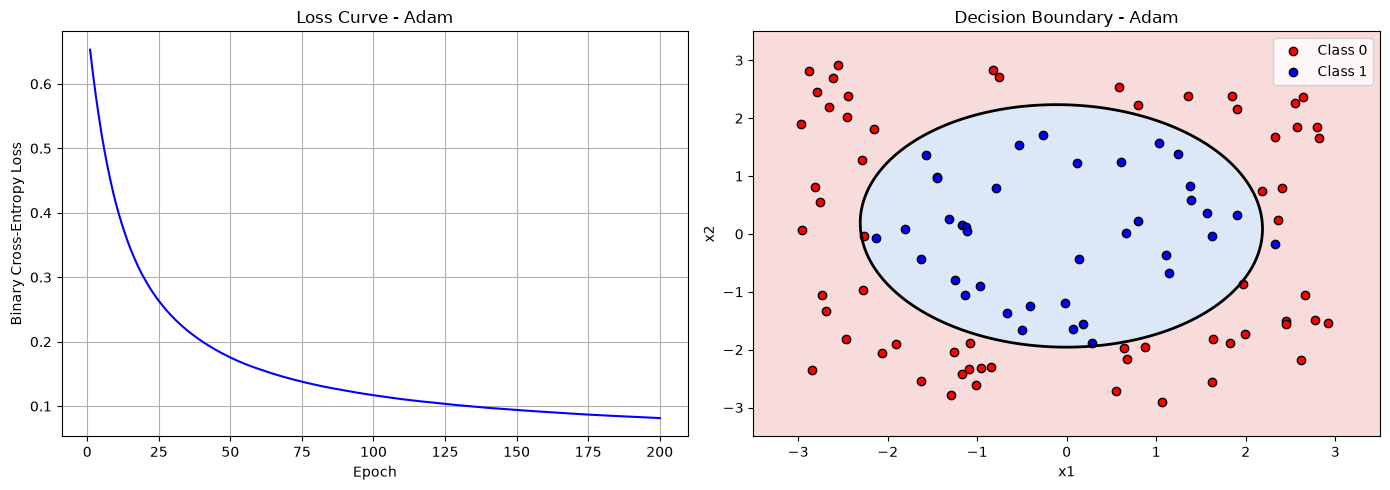

In [7]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
grid_points = np.c_[x1_grid.ravel(), x2_grid.ravel()]
grid_scaled = scaler.transform(poly.transform(grid_points))
grid_scaled[:, 0] = 1
grid_probabilities = sigmoid(grid_scaled @ weights).reshape(x1_grid.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(loss_history) + 1), loss_history, color="blue")
axes[0].set_title("Loss Curve - Adam")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].grid(True)

axes[1].contourf(x1_grid, x2_grid, grid_probabilities, levels=[0, 0.5, 1], colors=["#f4c6c6", "#c6d8f4"], alpha=0.6)
axes[1].contour(x1_grid, x2_grid, grid_probabilities, levels=[0.5], colors="black", linewidths=2)
axes[1].scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], color="red", edgecolor="black", label="Class 0")
axes[1].scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], color="blue", edgecolor="black", label="Class 1")
axes[1].set_title("Decision Boundary - Adam")
axes[1].set_xlabel("x1")
axes[1].set_ylabel("x2")
axes[1].legend()

plt.tight_layout()
plt.show()